In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
import torch.nn as nn
import torch.optim as optim

In [2]:
class one_D_mesh:
    def __init__(self, length, ne, nen, ndof_n):

        # Class inputs
        self.length = length
        self.ne = ne
        self.nen = nen
        self.ndof_n = ndof_n
        
        # Derived variables 
        self.nn = (self.nen-1)*self.ne+1
        self.e_length = self.length/self.ne
        self.ndof = self.nn*self.ndof_n

        # Connectivity array, coordinates array
        self.X_e, _  = self.discretize(ne,nen)
        _, self.coord = self.discretize(ne,nen)

    def discretize(self,ne, nen):

        coord = np.linspace(0, self.length, self.nn)
        X_e = np.zeros((ne, nen))

        for i in range(ne):

            X_e[i] = np.array([coord[i*(self.nen-1)], coord[i*(self.nen-1)+1], coord[i*(self.nen-1)+2]])
        
        return X_e, coord

In [3]:
mesh = one_D_mesh(1, 5, 3, 1)

In [4]:
# Collocation points, If i use 1 it does not work
x = torch.linspace(0,1,1000, requires_grad=True)

In [5]:
class quad_splines:
    def __init__(self, mesh):
        self.nn = mesh.nn
        self.coord = mesh.coord
        #Nodal values as trainable parameteres initialization(-1 because one is fixed, non-trainable for first order pde)
        # self.nodal_values = torch.zeros(self.nn-1, requires_grad=True)

        #Nodal values as trainable parameteres initialization(-2 because two are fixed, non-trainable for second order pde)
        self.nodal_values = torch.zeros(self.nn-2, requires_grad=True)
        
    
    def forward(self,x):

        self.N = torch.zeros(self.nn,x.shape[0])
        
        def is_even(n):
            return n % 2 == 0
        def is_odd(n):
            return n % 2 != 0
        def left_quadratic(x,i):
            cond = (x >= self.coord[i-2]) & (x <= self.coord[i])
            y = torch.where( cond , ((x-self.coord[i-2])*(x-self.coord[i-1]))/((self.coord[i]-self.coord[i-2])*(self.coord[i]-self.coord[i-1])), 0.0)
            return y

        def right_quadratic(x,i):
            cond = (x >= self.coord[i]) & (x < self.coord[i+2])
            y = torch.where( cond , ((x-self.coord[i+1])*(x-self.coord[i+2]))/((self.coord[i]-self.coord[i+1])*(self.coord[i]-self.coord[i+2])), 0.0)
            return y

        def center_quadratic(x,i):
            cond = (x >= self.coord[i-1]) & (x < self.coord[i+1])
            y = torch.where( cond , ((x-self.coord[i-1])*(x-self.coord[i+1]))/((self.coord[i]-self.coord[i-1])*(self.coord[i]-self.coord[i+1])), 0.0)
            return y

        def left_n_right_quadratic(x,i):
            cond1 = (x >= self.coord[i-2]) & (x < self.coord[i])
            cond2 = (x >= self.coord[i]) & (x < self.coord[i+2])
            y = torch.where( cond1 , ((x-self.coord[i-2])*(x-self.coord[i-1]))/((self.coord[i]-self.coord[i-2])*(self.coord[i]-self.coord[i-1])), torch.where(cond2, ((x-self.coord[i+1])*(x-self.coord[i+2]))/((self.coord[i]-self.coord[i+1])*(self.coord[i]-self.coord[i+2])),0.0))
            return y
        
        for i in range(self.nn):
            if i==0:
                self.N[i]=right_quadratic(x,i)
                continue
            if i==(self.nn-1):
                self.N[i]=left_quadratic(x,i)
                continue
            if is_odd(i):
                self.N[i]=center_quadratic(x,i)
            if is_even(i):
                self.N[i]=left_n_right_quadratic(x,i)
        
        # weighted sum of the hat functions with the nodal values. 
        # Here we are imposing the BC for u(0)=0 by ignoring the first shape function because is zero(N[1:]). 
        # If we have a different DC we have to add + u_0*N[0]

        # for first order pde we are imposing one BC condition.
        # y = self.nodal_values@N[1:]

        # for second order pde we are imposing two BC conditions.
        y = self.nodal_values@self.N[1:-1]


        return y

In [6]:
model = quad_splines(mesh)


In [7]:
y = model.forward(x)

In [24]:
# import sys
# sys.path.append(r'C:\Users\Polydoras\Documents\Sisc\PhD\PI_bsplines')  # Adjust path accordingly

# from plot_style import set_plot_style

# set_plot_style()


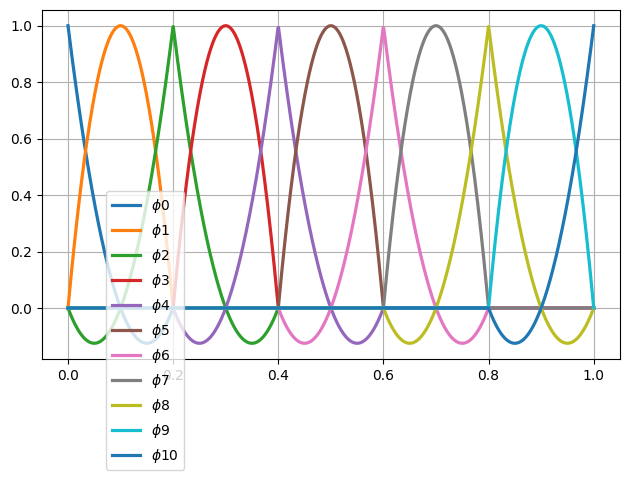

In [14]:
plt.grid(True)
for i in range(model.nn):
    plt.plot(x.detach().numpy(), model.N[i].detach().numpy(), linewidth=2.3, label=fr"$\phi{i}$")

plt.legend(framealpha=0)  # 0.0 = fully transparent, 1.0 = opaque
plt.legend(loc="upper left", bbox_to_anchor=(0.1, 0.5))
plt.tight_layout()
plt.show()

In [7]:
# Learning rate
learning_rate = 0.00001

# Number of iterations
epochs = 10000

# Training loop (manual gradient descent)
for epoch in range(epochs):
    # Forward pass: y = slope * x + intercept
    # y_pred = torch.einsum('bij,bi->j',phi, nodal_values)
    y_pred = model.forward(x)
    
    # Compute model first derivative wrt x
    grad_u_x=torch.autograd.grad(y_pred, x, grad_outputs=torch.ones_like(y_pred), create_graph=True)[0]

    # Compute model second derivative wrt x
    grad_u_xx=torch.autograd.grad(grad_u_x, x, grad_outputs=torch.ones_like(y_pred), create_graph=True)[0]

    # physics loss
    # loss = torch.mean((grad_u_x - 2*x) ** 2) 
    # loss = torch.mean((grad_u_xx - 2) ** 2)/10
    # Poisson 
    loss = torch.mean((grad_u_xx + 1) ** 2)/10

    # Compute Mean Squared Error (MSE) loss
    # loss = torch.mean((y_pred - y) ** 2)
    
    # Backward pass: compute gradients
    loss.backward()
    
    # Manually update parameters using the gradients
    with torch.no_grad():
        model.nodal_values -= learning_rate * model.nodal_values.grad
    
    # Zero the gradients after each update
    model.nodal_values.grad.zero_()
    # x.grad.zero_()
    
    # Print loss and parameters every 100 iterations
    if (epoch + 1) % 5 == 0:
        print(f'Epoch [{epoch + 1}/{epochs}], Loss: {loss.item()}')

Epoch [5/10000], Loss: 0.07922371476888657
Epoch [10/10000], Loss: 0.059313274919986725
Epoch [15/10000], Loss: 0.044496990740299225
Epoch [20/10000], Loss: 0.03345625847578049
Epoch [25/10000], Loss: 0.025216545909643173
Epoch [30/10000], Loss: 0.019057143479585648
Epoch [35/10000], Loss: 0.014444619417190552
Epoch [40/10000], Loss: 0.010983824729919434
Epoch [45/10000], Loss: 0.008381759747862816
Epoch [50/10000], Loss: 0.0064209639094769955
Epoch [55/10000], Loss: 0.0049398415721952915
Epoch [60/10000], Loss: 0.0038181785494089127
Epoch [65/10000], Loss: 0.002966411644592881
Epoch [70/10000], Loss: 0.002317722886800766
Epoch [75/10000], Loss: 0.0018221879145130515
Epoch [80/10000], Loss: 0.0014424349647015333
Epoch [85/10000], Loss: 0.0011504378635436296
Epoch [90/10000], Loss: 0.0009251371957361698
Epoch [95/10000], Loss: 0.0007506775436922908
Epoch [100/10000], Loss: 0.0006150886765681207
Epoch [105/10000], Loss: 0.0005093154031783342
Epoch [110/10000], Loss: 0.0004264877061359584

In [9]:
# Impose BC y=0
x = torch.linspace(0,1,1000, requires_grad=True)

y_pred=model.forward(x)

In [13]:
np.save('y_pred_FEM.npy', y_pred.detach().numpy())

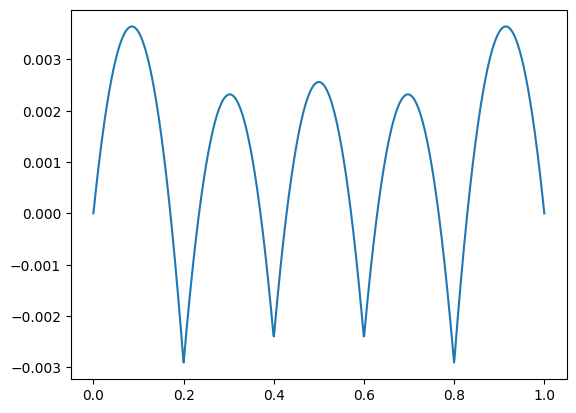

In [10]:
plt.plot(x.detach().numpy(),y_pred.detach().numpy())
# plt.plot(x.detach().numpy(),(x**2).detach().numpy())


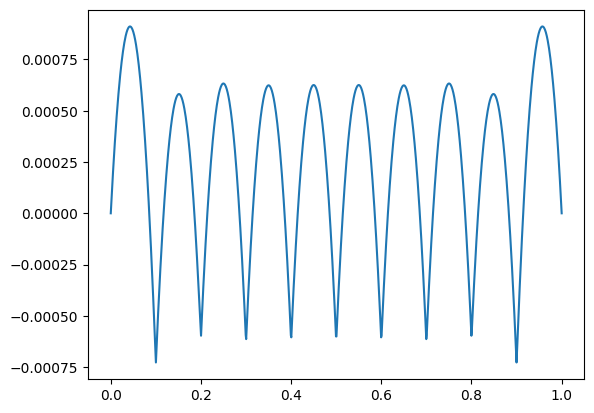

In [23]:
plt.plot(x.detach().numpy(),y_pred.detach().numpy())
# plt.plot(x.detach().numpy(),(x**2).detach().numpy())


PINN solution of 1D Poisson equation

Epoch 0, Loss: 0.8652175068855286
Epoch 1000, Loss: 4.304741742089391e-05
Epoch 2000, Loss: 2.0933141058776528e-05
Epoch 3000, Loss: 6.7463156483427156e-06
Epoch 4000, Loss: 1.6059318568295566e-06
Epoch 5000, Loss: 2.5380012402820284e-07
Epoch 6000, Loss: 1.3916256591528509e-07
Epoch 7000, Loss: 1.2399307536270499e-07
Epoch 8000, Loss: 1.165886232001867e-07
Epoch 9000, Loss: 8.000186426215805e-06


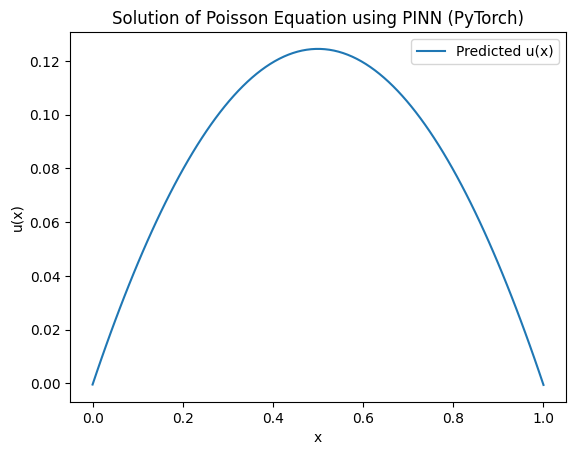

In [32]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import matplotlib.pyplot as plt

# Define the neural network architecture for the PINN
class PINN(nn.Module):
    def __init__(self):
        super(PINN, self).__init__()
        self.hidden1 = nn.Linear(1, 50)
        self.hidden2 = nn.Linear(50, 50)
        self.output_layer = nn.Linear(50, 1)

    def forward(self, x):
        x = torch.tanh(self.hidden1(x))
        x = torch.tanh(self.hidden2(x))
        return self.output_layer(x)

# Define the loss function (physics-informed loss)
def loss(model, x, f_x, u_0, u_1):
    x.requires_grad = True
    
    # Forward pass
    u = model(x)  # Neural network output u(x)
    
    # Compute the second derivative of u(x)
    u_x = torch.autograd.grad(u, x, grad_outputs=torch.ones_like(u), create_graph=True)[0]
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    
    # PDE residual: -u''(x) - f(x) = 0
    pde_loss = torch.mean((u_xx + f_x)**2)
    
    # Boundary conditions loss: u(0) = u_0, u(1) = u_1
    bc_loss = torch.mean((model(torch.tensor([[0.0]])) - u_0)**2) + \
              torch.mean((model(torch.tensor([[1.0]])) - u_1)**2)
    
    return pde_loss + bc_loss

# Domain and boundary conditions
L = 1.0  # Length of the domain
x_train = np.linspace(0, L, 100)  # Training points in the domain
f_x = np.ones_like(x_train)  # Source term f(x) = 1
u_0 = 0  # Boundary condition at x = 0
u_1 = 0  # Boundary condition at x = 1

# Convert to PyTorch tensors
x_train_tensor = torch.tensor(x_train[:, None], dtype=torch.float32)

# Initialize the neural network and optimizer
model = PINN()
optimizer = optim.Adam(model.parameters(), lr=0.001)

# Training loop
epochs = 10000
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # Compute the loss
    current_loss = loss(model, x_train_tensor, torch.tensor(f_x[:, None], dtype=torch.float32), u_0, u_1)
    
    # Backpropagate and optimize
    current_loss.backward()
    optimizer.step()
    
    # Print the loss every 1000 iterations
    if epoch % 1000 == 0:
        print(f"Epoch {epoch}, Loss: {current_loss.item()}")

# Plot the solution after training
x_test = np.linspace(0, L, 100)[:, None]
x_test_tensor = torch.tensor(x_test, dtype=torch.float32)
u_pred = model(x_test_tensor).detach().numpy()

# Plot the predicted solution
plt.plot(x_test, u_pred, label="Predicted u(x)")
plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Solution of Poisson Equation using PINN (PyTorch)')
plt.legend()
plt.show()


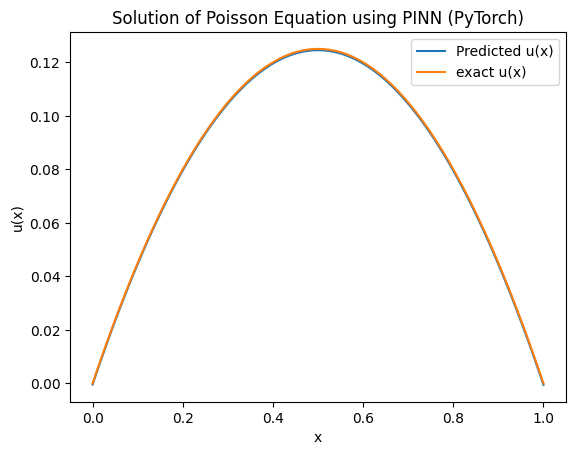

In [36]:
plt.plot(x_test, u_pred, label="Predicted u(x)")
plt.plot(x_test, -(x_test**2)/2+1/2*x_test, label="exact u(x)")

plt.xlabel('x')
plt.ylabel('u(x)')
plt.title('Solution of Poisson Equation using PINN (PyTorch)')
plt.legend()
plt.show()

PINN in 2D Poisson 

In [2]:
import torch
import torch.nn as nn
import numpy as np

# Neural Network definition
class PINN(nn.Module):
    def __init__(self, layers):
        super(PINN, self).__init__()
        self.model = nn.Sequential()
        for i in range(len(layers)-1):
            self.model.add_module(f"layer_{i}", nn.Linear(layers[i], layers[i+1]))
            if i != len(layers) - 2:
                self.model.add_module(f"tanh_{i}", nn.Tanh())

    def forward(self, x):
        return self.model(x)

# Source term f(x, y)
def f(x, y):
    return torch.sin(np.pi * x) * torch.sin(np.pi * y)

# Compute the PDE residual
def pde_residual(model, x, y):
    x.requires_grad_(True)
    y.requires_grad_(True)
    u = model(torch.cat([x, y], dim=1))
    
    grads = torch.autograd.grad(u, [x, y], grad_outputs=torch.ones_like(u), create_graph=True)
    u_x, u_y = grads
    u_xx = torch.autograd.grad(u_x, x, grad_outputs=torch.ones_like(u_x), create_graph=True)[0]
    u_yy = torch.autograd.grad(u_y, y, grad_outputs=torch.ones_like(u_y), create_graph=True)[0]
    
    return u_xx + u_yy + f(x, y)  # Poisson: Δu = -f

# Training data
N_f = 10000  # Collocation points in the domain
N_b = 400    # Boundary points

# Collocation points
x_f = torch.rand((N_f, 1), requires_grad=True)
y_f = torch.rand((N_f, 1), requires_grad=True)

# Boundary: assume Dirichlet on unit square
x_b = torch.cat([torch.rand((N_b//4, 1)), torch.zeros((N_b//4, 1))], dim=1)
x_b = torch.cat([x_b, torch.cat([torch.rand((N_b//4, 1)), torch.ones((N_b//4, 1))], dim=1)], dim=0)
x_b = torch.cat([x_b, torch.cat([torch.zeros((N_b//4, 1)), torch.rand((N_b//4, 1))], dim=1)], dim=0)
x_b = torch.cat([x_b, torch.cat([torch.ones((N_b//4, 1)), torch.rand((N_b//4, 1))], dim=1)], dim=0)

u_b = torch.zeros((N_b, 1))  # Zero Dirichlet BC

# Model, optimizer
model = PINN([2, 64, 64, 64, 1])
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Training loop
epochs = 5000
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # Residual loss
    res = pde_residual(model, x_f, y_f)
    loss_f = torch.mean(res**2)
    
    # Boundary loss
    u_pred = model(x_b)
    loss_b = torch.mean((u_pred - u_b)**2)
    
    loss = loss_f + loss_b
    loss.backward()
    optimizer.step()
    
    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")



Epoch 0, Loss: 0.278494
Epoch 500, Loss: 0.000217
Epoch 1000, Loss: 0.000015
Epoch 1500, Loss: 0.000011
Epoch 2000, Loss: 0.000009
Epoch 2500, Loss: 0.000009


KeyboardInterrupt: 

In [ ]:
model.coeff.grad

Epoch 0, Loss: 95.876793
Epoch 500, Loss: 0.736824
Epoch 1000, Loss: 0.083327
Epoch 1500, Loss: 0.058995
Epoch 2000, Loss: 0.046891
Epoch 2500, Loss: 0.038855
Epoch 3000, Loss: 0.031790
Epoch 3500, Loss: 0.025092
Epoch 4000, Loss: 0.018922
Epoch 4500, Loss: 0.013977
Epoch 5000, Loss: 0.010446
Epoch 5500, Loss: 0.008197
Epoch 6000, Loss: 0.006976
Epoch 6500, Loss: 0.006060
Epoch 7000, Loss: 0.005213
Epoch 7500, Loss: 0.004782
Epoch 8000, Loss: 0.003704
Epoch 8500, Loss: 0.003069
Epoch 9000, Loss: 0.002538
Epoch 9500, Loss: 0.002558


AttributeError: 'AxesSubplot' object has no attribute 's'

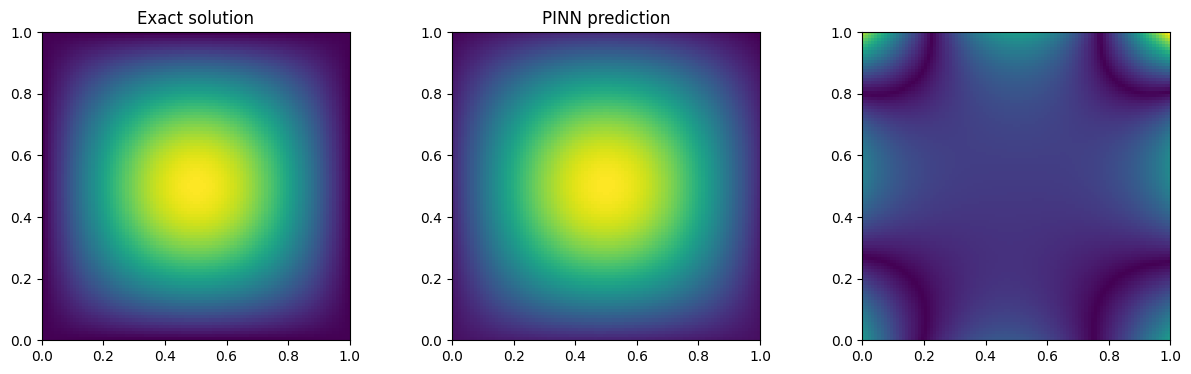

In [4]:
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Exact solution and RHS function
def u_exact(x, y):
    return torch.sin(torch.pi * x) * torch.sin(torch.pi * y)

def f_exact(x, y):
    return 2 * torch.pi**2 * torch.sin(torch.pi * x) * torch.sin(torch.pi * y)

# Simple neural network model
class PINN(nn.Module):
    def __init__(self):
        super(PINN, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(2, 20),
            nn.Tanh(),
            nn.Linear(20, 20),
            nn.Tanh(),
            nn.Linear(20, 1)
        )

    def forward(self, x):
        return self.net(x)

# Sample domain points
def sample_domain(n_interior, n_boundary):
    interior = torch.rand((n_interior, 2))

    # Boundary points
    x = torch.linspace(0, 1, n_boundary)
    xb = torch.cat([
        torch.stack([x, torch.zeros_like(x)], dim=1),
        torch.stack([x, torch.ones_like(x)], dim=1),
        torch.stack([torch.zeros_like(x), x], dim=1),
        torch.stack([torch.ones_like(x), x], dim=1)
    ], dim=0)

    return interior, xb

# Set up model and optimizer
model = PINN()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

# Sample collocation and boundary points
n_interior = 2000
n_boundary = 100
interior_pts, boundary_pts = sample_domain(n_interior, n_boundary)
interior_pts.requires_grad_(True)






In [5]:
# Training loop
epochs = 10000

for epoch in range(epochs):
    optimizer.zero_grad()

    # PDE loss
    u_pred = model(interior_pts)
    grads = torch.autograd.grad(u_pred, interior_pts, grad_outputs=torch.ones_like(u_pred), create_graph=True)[0]
    u_x = grads[:, 0:1]
    u_y = grads[:, 1:2]
    u_xx = torch.autograd.grad(u_x, interior_pts, grad_outputs=torch.ones_like(u_x), create_graph=True)[0][:, 0:1]
    u_yy = torch.autograd.grad(u_y, interior_pts, grad_outputs=torch.ones_like(u_y), create_graph=True)[0][:, 1:2]
    laplace_u = u_xx + u_yy
    f_val = f_exact(interior_pts[:, 0:1], interior_pts[:, 1:2])
    loss_pde = torch.mean((laplace_u + f_val)**2)

    # Boundary loss
    u_bc = model(boundary_pts)
    loss_bc = torch.mean(u_bc**2)

    loss = loss_pde + loss_bc
    loss.backward()
    optimizer.step()

    if epoch % 500 == 0:
        print(f"Epoch {epoch}, Loss: {loss.item():.6f}")

Epoch 0, Loss: 0.002057
Epoch 500, Loss: 0.001596
Epoch 1000, Loss: 0.001489
Epoch 1500, Loss: 0.001254
Epoch 2000, Loss: 0.001115
Epoch 2500, Loss: 0.001003
Epoch 3000, Loss: 0.000908
Epoch 3500, Loss: 0.000844
Epoch 4000, Loss: 0.000756
Epoch 4500, Loss: 0.000695
Epoch 5000, Loss: 0.000638
Epoch 5500, Loss: 0.000596
Epoch 6000, Loss: 0.000546
Epoch 6500, Loss: 0.000508
Epoch 7000, Loss: 0.000473
Epoch 7500, Loss: 0.000677
Epoch 8000, Loss: 0.000413
Epoch 8500, Loss: 0.000438
Epoch 9000, Loss: 0.000446
Epoch 9500, Loss: 0.000416


AttributeError: 'AxesSubplot' object has no attribute 's'

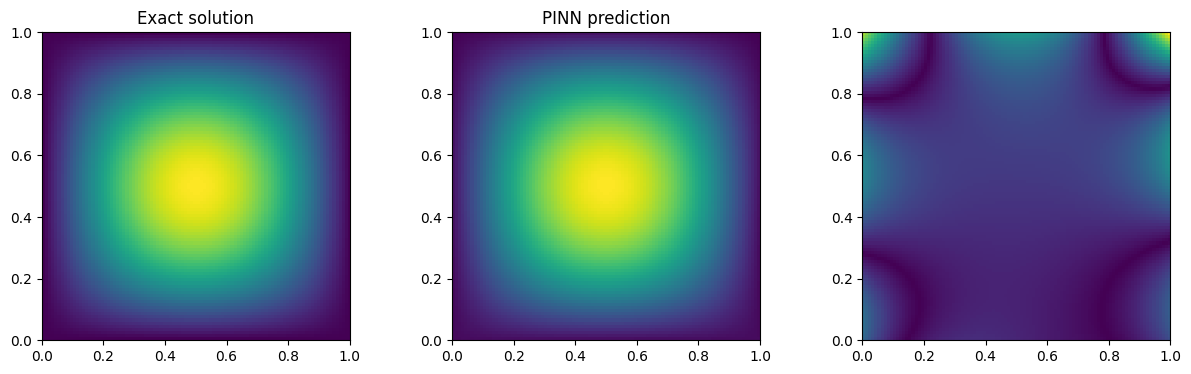

In [6]:
# Evaluation on grid
N = 100
x = torch.linspace(0, 1, N)
y = torch.linspace(0, 1, N)
X, Y = torch.meshgrid(x, y, indexing='ij')
XY = torch.cat([X.reshape(-1, 1), Y.reshape(-1, 1)], dim=1)

with torch.no_grad():
    u_pred_grid = model(XY).reshape(N, N)
    u_true_grid = u_exact(X, Y)

# Plot results
fig, axs = plt.subplots(1, 3, figsize=(15, 4))
axs[0].imshow(u_true_grid, extent=[0,1,0,1], origin='lower')
axs[0].set_title("Exact solution")
axs[1].imshow(u_pred_grid, extent=[0,1,0,1], origin='lower')
axs[1].set_title("PINN prediction")
axs[2].imshow(torch.abs(u_pred_grid - u_true_grid), extent=[0,1,0,1], origin='lower')
axs[2].s


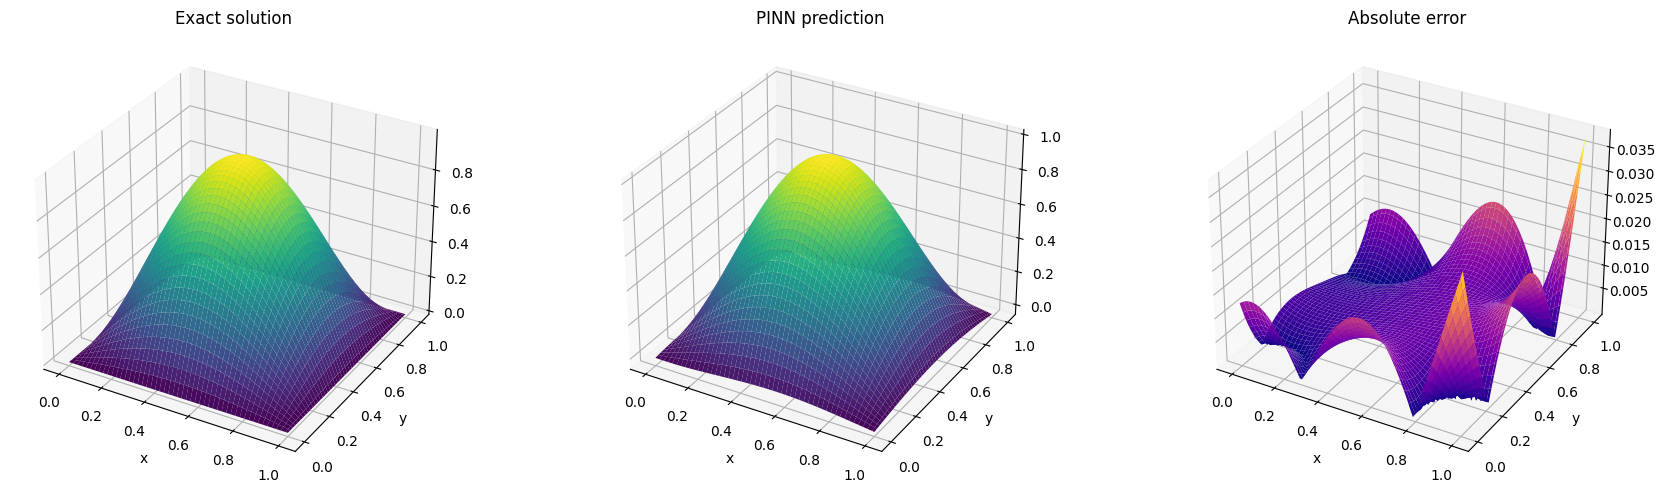

In [8]:
from mpl_toolkits.mplot3d import Axes3D

fig = plt.figure(figsize=(18, 5))

# Exact solution
ax1 = fig.add_subplot(131, projection='3d')
ax1.plot_surface(X.numpy(), Y.numpy(), u_true_grid.numpy(), cmap='viridis')
ax1.set_title("Exact solution")
ax1.set_xlabel('x')
ax1.set_ylabel('y')

# PINN prediction
ax2 = fig.add_subplot(132, projection='3d')
ax2.plot_surface(X.numpy(), Y.numpy(), u_pred_grid.numpy(), cmap='viridis')
ax2.set_title("PINN prediction")
ax2.set_xlabel('x')
ax2.set_ylabel('y')

# Absolute error
ax3 = fig.add_subplot(133, projection='3d')
ax3.plot_surface(X.numpy(), Y.numpy(), torch.abs(u_pred_grid - u_true_grid).numpy(), cmap='plasma')
ax3.set_title("Absolute error")
ax3.set_xlabel('x')
ax3.set_ylabel('y')

plt.tight_layout()
plt.show()